
# Iris Flower Classification

## Introduction

This project is part of my Oasis Infobyte Data Science internship.

The aim is to build a machine learning model that predicts the species of an iris flower using its measurements.

The three species are Setosa, Versicolor, and Virginica.

## Project Objectives

- Explore the Iris dataset.
- Check the data for missing values and understand its structure.
- Create visualisations to compare the flower species.
- Train and evaluate at least two classification models.
- Compare the results and identify the best-performing model.



## 1. Loading the Dataset

The Iris dataset is already available from the scikit-learn library.

It contains measurements of iris flowers from the three different species. We will load the dataset and explore its features and target labels before doing our analysis.



In [1]:
#import pandas so we can work with tables
import pandas as pd

#import the Iris dataset
from sklearn.datasets import load_iris

#load the dataset
iris = load_iris()

#create a table containing the 4 flower measurements
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

#add the actual flower species to the table
df["species"] = iris.target_names[iris.target]

#display the first 5 rows
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
#check the number of rows and columns
print("Dataset shape:", df.shape)

#check the data types of each column
print("\nColumn data types:")
print(df.dtypes)

#check for missing values in each column
print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (150, 5)

Column data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species               object
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64


In [3]:
#calculate descriptive statistics for the flower measurements
df.describe()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


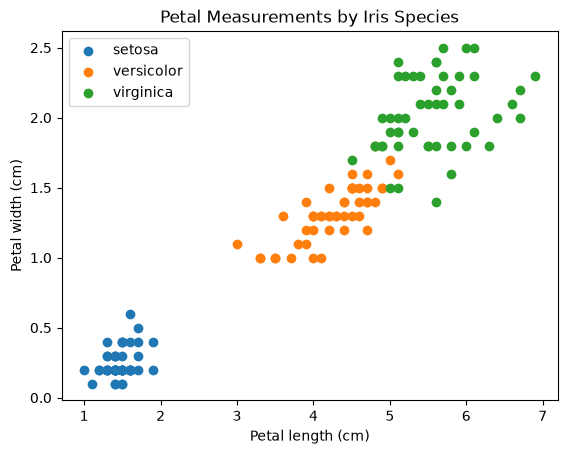

In [4]:
#import the plotting library
import matplotlib.pyplot as plt

#create a scatter plot
for species in df["species"].unique():
    species_data = df[df["species"] == species]

    plt.scatter(
        species_data["petal length (cm)"],
        species_data["petal width (cm)"],
        label=species
    )

#add labels and a title
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.title("Petal Measurements by Iris Species")

#display the legend and graph
plt.legend()
plt.show()


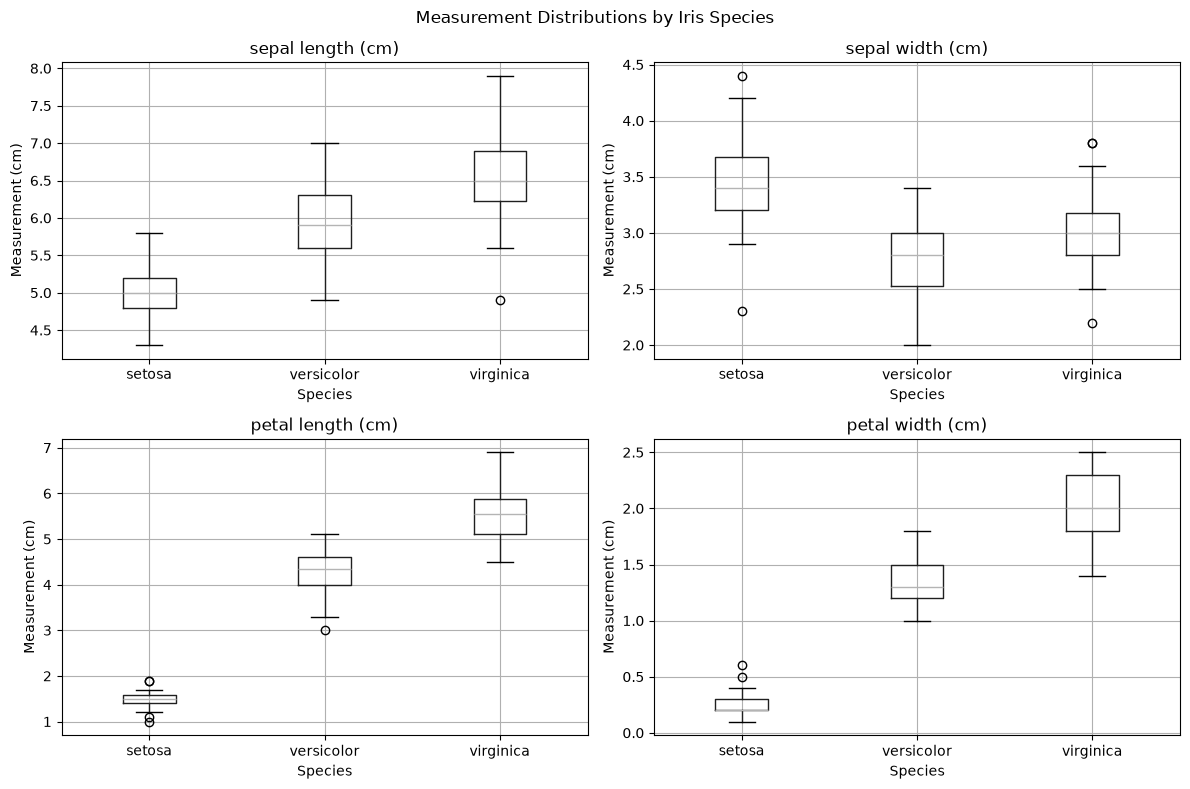

In [ ]:
#create a figure with 4 box plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

#list the 4 measurements
features = iris.feature_names

#draw 1 box plot for each measurement
for ax, feature in zip(axes.flatten(), features):
    df.boxplot(column=feature, by="species", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")

#add a heading to the whole figure
plt.suptitle("Measurement Distributions by Iris Species")
plt.tight_layout()
plt.show()



## Exploratory Data Analysis Findings

The Iris dataset contains 150 flower samples, 4 numerical
features, and 1 target column called species. The dataset
contains no missing values.

The scatter plot comparing petal length and petal width shows
that Setosa forms a clearly separate group. Versicolor and
Virginica have larger petal measurements and show some overlap.

The box plots allow us to compare the distribution of all four
measurements across the three species. The petal measurements
appear particularly useful for distinguishing the flower species.

These findings suggest that petal length and petal width may be
important features for training a classification model.



## 5. Preparing the Data for Machine Learning

In this section, we will be separating the flower measurements from the species labels. The dataset will then be divided into training and testing sets.

The training data will be used to teach the classification
models, while the testing data will help us evaluate how
accurately they predict flower species on unseen samples.


In [5]:
#select the 4 flower measurements as our features
X = df[iris.feature_names]

#select the species column as our target
Y = df["species"]

#display the shapes of the features and target
print("Features shape:", X.shape)
print("Target shape:", Y.shape)

#display the first 5 target values
print("\nFirst five target values:")
print(Y.head())


Features shape: (150, 4)
Target shape: (150,)

First five target values:
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


In [6]:
#import the function for splitting the dataset
from sklearn.model_selection import train_test_split

#split the data into training and testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

#display the sizes of the new datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", Y_train.shape)
print("Testing labels:", Y_test.shape)


Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)



## 6. Training the Machine Learning Models

### Model 1: Logistic Regression

Logistic Regression is a supervised machine-learning algorithm
used for classification. It learns relationships between the
flower measurements and their species labels to predict the
species of unseen flowers.


In [9]:
#import the logistic regression classifier
from sklearn.linear_model import LogisticRegression

#create the model
logistic_model = LogisticRegression(max_iter=200)

#train the model using the training data
logistic_model.fit(X_train, Y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [10]:
#import evaluation tools
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

#use the trained model to predict flower species
Y_pred = logistic_model.predict(X_test)

#calculate the model's accuracy
accuracy = accuracy_score(Y_test, Y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

#display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, Y_pred))

#display precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(Y_test, Y_pred))


Logistic Regression Accuracy: 96.67 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30




### Logistic Regression Evaluation

The Logistic Regression model achieved an accuracy of 96.67%
on the test dataset, correctly classifying 29 out of 30 flowers.

The confusion matrix shows that all Setosa and Virginica
samples were correctly identified. One Versicolor sample
was incorrectly classified as Virginica.

Setosa achieved precision, recall, and F1-scores of 1.00.
The results suggest that Logistic Regression performs well
on this dataset, although some confusion remains between
Versicolor and Virginica.

A second classification model will be trained and evaluated
to compare its performance with Logistic Regression.



### Model 2: K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised classification algorithm
that predicts a sample's class using the classes of its nearest
neighbours in the training dataset.

In this project, we will evaluate KNN alongside Logistic
Regression to compare classification performance.


In [12]:
#import the K-Nearest Neighbors classifier
from sklearn.neighbors import KNeighborsClassifier

#create the KNN model using 5 neighbours
knn_model = KNeighborsClassifier(n_neighbors=5)

#train the model
knn_model.fit(X_train, Y_train)

print("KNN model trained successfully!")


KNN model trained successfully!


In [14]:
#use KNN to predict the species of the test flowers
knn_predictions = knn_model.predict(X_test)

#calculate the accuracy
knn_accuracy = accuracy_score(Y_test, knn_predictions)

print("KNN Accuracy:", round(knn_accuracy * 100, 2), "%")

#display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(Y_test, knn_predictions))

#display the classification report
print("\nClassification Report:")
print(classification_report(Y_test, knn_predictions))


KNN Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



In [15]:
#compare the accuracy of both models
print("Model Accuracy Comparison")
print("-------------------------")
print("Logistic Regression:", round(accuracy * 100, 2), "%")
print("K-Nearest Neighbors:", round(knn_accuracy * 100, 2), "%")


Model Accuracy Comparison
-------------------------
Logistic Regression: 96.67 %
K-Nearest Neighbors: 100.0 %



## 7. Model Comparison and Selection

Two classification algorithms were trained and evaluated, namely:
Logistic Regression and K-Nearest Neighbors (KNN).

Logistic Regression achieved 96.67% accuracy, correctly
classifying 29 out of 30 test samples.

KNN achieved 100% accuracy, correctly classifying all
30 test samples.

Based on test accuracy, KNN performed better on this split
of the Iris dataset. It is therefore selected as the best
performing model in this experiment.

However, this result is based on a single train-test split.
Further testing, such as cross-validation, could help determine whether KNN generalises consistently to unseen flower samples.



## 8. Conclusion

This project used machine learning to classify Iris flowers
based on sepal and petal measurements.

The dataset contained 150 samples, four numerical features,
and three flower species. Exploratory data analysis showed
that petal length and petal width were useful for distinguishing
the species.

Two classification models were evaluated. Logistic Regression
achieved 96.67% test accuracy, while K-Nearest Neighbors
achieved 100% test accuracy.

KNN performed best on the test set used in this experiment.
The project demonstrates how data exploration, visualisation,
model training, and evaluation can be used to solve a
classification problem.
